# L1-c · Market features only

Standardized JISDOR features → Tuned Regularized MLP → P(UP). No text, news counts, or macro series. UP = USD/IDR rises (IDR depreciates).

**Methodological Improvements & Loophole Remediation:**
1. **Nested Chronological Split (Loophole 1.1):** Model selection is separated from evaluation using nested expanding folds (Train, Validation, and untouched Test).
2. **Loss-Based Early Stopping & Warm-up (Loophole 1.2):** Enforces 15 epochs of warm-up and optimizes smooth validation cross-entropy (log-loss) with patience 40.
3. **Regularized Hyperparameter Tuning (Loophole 1.4):** Searches over compact, highly regularized architectures `(16,)`, `(32,)`, `(16, 8)`, `(32, 16)` with L2 $\alpha \in \{0.01, 0.1\}$ on inner validation to prevent overparameterization on tabular data.
4. **Platt Calibration & Threshold Tuning (Loophole 1.5):** Calibrates probabilities via Platt scaling and tunes the decision threshold on validation data to address class imbalance.
5. **Locked Final Test Unlocked (Loophole 1.3):** Evaluates the frozen winning configuration on the untouched 235-day holdout (2025-08-29 to 2026-08-31) exactly once.
6. **Variance & Effect Size Reporting (Loophole 1.6):** Reports paired fold metrics, seed standard deviation, and moving-block bootstrap confidence intervals.

Use the [shared split](../../SPLIT_PROTOCOL.md) and [ablation protocol](../../rules/ablation_protocol.md). Dependencies: NumPy, pandas, Matplotlib, scikit-learn. Outputs stay inside this notebook.

In [1]:
from pathlib import Path
import copy
import hashlib
import json
import platform
import time
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.dates as mdates
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "deira-work/SPLIT_PROTOCOL.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a directory beneath it.")
BASE = ROOT / "deira-work/preprocessing/outputs/date_delay_sensitivity__audit_only"
MODEL_ID = "L1-c"
SEEDS = [42, 123, 2026]
MAX_EPOCHS = 150
WARMUP_EPOCHS = 15       # Minimum training epochs before early stopping can trigger
PATIENCE = 40            # Extended patience to allow optimizer to traverse noisy plateaus
MIN_DELTA = 1e-4         # Minimum improvement threshold in validation loss

# Regularized search space for nested hyperparameter optimization (Loophole 1.4)
PARAM_GRID = [
    {"hidden_layer_sizes": (16,), "alpha": 1e-2, "learning_rate_init": 1e-3},
    {"hidden_layer_sizes": (32,), "alpha": 1e-2, "learning_rate_init": 1e-3},
    {"hidden_layer_sizes": (16, 8), "alpha": 1e-2, "learning_rate_init": 1e-3},
    {"hidden_layer_sizes": (32, 16), "alpha": 1e-2, "learning_rate_init": 1e-3},
    {"hidden_layer_sizes": (16,), "alpha": 1e-1, "learning_rate_init": 1e-3},
    {"hidden_layer_sizes": (32,), "alpha": 1e-1, "learning_rate_init": 1e-3},
]

RUN_FINAL_TEST = True    # Evaluated exactly once on the untouched holdout after freezing settings (Loophole 1.3)
BOOTSTRAP_REPEATS = 1000
BLOCK_LENGTH = 10        # Evaluated fixing observations; circular moving blocks.
BOOTSTRAP_SEED = 20261110
LABELS = ["DOWN", "UP"]
METRICS = ["mcc", "macro_f1", "balanced_accuracy", "accuracy", "roc_auc", "brier", "log_loss", "ece_10"]
COLORS = ["#2563eb", "#ea580c", "#059669", "#9333ea"]
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"{MODEL_ID} | seeds: {SEEDS} | grid size: {len(PARAM_GRID)} | warmup: {WARMUP_EPOCHS} | patience: {PATIENCE} | final test enabled: {RUN_FINAL_TEST}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"scikit-learn {sklearn.__version__}")

L1-c | seeds: [42, 123, 2026] | grid size: 6 | warmup: 15 | patience: 40 | final test enabled: True
Python 3.10.14 | pandas 2.3.3 | NumPy 1.26.4 | Matplotlib 3.10.6
scikit-learn 1.7.2


## Shared data

Reuse the exact eligible dates, labels, and purges from L1-a/L1-b. Read predictors only from `feature_contract.json`. Targets, future gaps, and news availability never enter this model.

**Three-Way Chronological Split Protocol:**
To remove circular validation leakage:
- **Inner Train:** Chronological first 80% of development observations within each fold. Scaler and model weights are fitted exclusively on this partition.
- **Inner Validation:** Chronological remaining 20% of the training window (with target-boundary purge). Used strictly for early stopping and checkpoint selection.
- **Held-Out Test:** The untouched forward chronological evaluation window (158, 159, 158 decisions; 475 total unique dates). Scored only once on the final selected checkpoint.

In [2]:
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
pipeline = json.loads((BASE / "pipeline_manifest.json").read_text())
for name, expected in pipeline["input_sha256"].items():
    assert sha256(ROOT / name) == expected, f"Source snapshot changed: {name}"
assert pipeline["config"]["alignment_mode"] == "date_delay_sensitivity"
assert pipeline["config"]["geopolitical_policy"] == "audit_only"

contract = json.loads((BASE / "feature_contract.json").read_text())
FEATURES = contract["market_features"]
assert not set(FEATURES) & set(contract["target_and_diagnostic_columns_never_predictors"])
assert not set(FEATURES) & {"n_berita", "has_news", "y", "target_date", "next_jisdor"}
assert len(FEATURES) == len(set(FEATURES))
folds = pd.read_csv(BASE / "fold_manifest.csv", parse_dates=["Date", "target_date"])
final = pd.read_csv(BASE / "final_fit_manifest.csv", parse_dates=["Date", "target_date"])
daily = pd.read_csv(BASE / "daily_market.csv", parse_dates=["Date", "target_date"])
partitions = pd.read_csv(BASE / "calendar_partitions.csv", parse_dates=["Date", "target_date"])
assert not daily.Date.duplicated().any()
assert not folds.duplicated(["fold", "role", "Date"]).any()
assert not final.Date.duplicated().any()

def take_rows(rows):
    fields = ["Date", "target_date", "y", "eligible_binary", "n_berita", "has_news",
              "target_weekday", "realized_target_gap_days", *FEATURES]
    joined = rows.merge(daily[fields], on="Date", how="left", validate="one_to_one", suffixes=("", "_daily"))
    assert len(joined) == len(rows) and joined.eligible_binary.all()
    assert joined.y.notna().all() and joined.y.isin([0, 1]).all()
    assert joined.target_date.eq(joined.target_date_daily).all()
    assert joined.y.eq(joined.y_daily).all()
    assert joined.n_berita.eq(joined.n_berita_daily).all()
    if "has_news_daily" in joined:
        assert joined.has_news.eq(joined.has_news_daily).all()
    assert np.isfinite(joined[FEATURES].to_numpy(dtype=float)).all()
    return joined.drop(columns=[c for c in joined if c.endswith("_daily")]).sort_values("Date").reset_index(drop=True)

split_summary = []
seen_test_dates = set()
for fold_id in sorted(folds.fold.unique()):
    train_full = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    test = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    
    # Chronological inner split: 80% inner train, 20% inner validation (purged of target overlap)
    split_idx = int(len(train_full) * 0.8)
    inner_train = train_full.iloc[:split_idx].copy().reset_index(drop=True)
    inner_val = train_full.loc[train_full.Date > inner_train.target_date.max()].copy().reset_index(drop=True)
    
    assert inner_train.target_date.max() < inner_val.Date.min()
    assert inner_val.target_date.max() < test.Date.min()
    assert not set(inner_train.Date) & set(inner_val.Date)
    assert not set(inner_val.Date) & set(test.Date)
    assert not seen_test_dates & set(test.Date)
    seen_test_dates.update(test.Date)
    
    for role, frame in [("train", inner_train), ("validation", inner_val), ("test", test)]:
        split_summary.append({"run": f"fold_{fold_id}", "role": role, "n": len(frame),
                              "first": frame.Date.min().date(), "last": frame.Date.max().date(),
                              "down": int(frame.y.eq(0).sum()), "up": int(frame.y.eq(1).sum()),
                              "news_days": int(frame.has_news.sum())})

final_train = take_rows(final.loc[final.role.eq("train")])
test_dates = final.loc[final.role.eq("test"), "Date"]
assert final_train.target_date.max() < test_dates.min()
assert not set(final_train.Date) & set(test_dates)
display(pd.DataFrame(split_summary))
print(f"Locked test: {test_dates.min().date()} to {test_dates.max().date()} | {len(test_dates)} eligible decisions")
print("Predictors:", ", ".join(FEATURES))

      run        role    n       first        last  down   up  news_days
0  fold_1       train  362  2021-09-29  2023-03-17   151  211         55
1  fold_1  validation   90  2023-03-21  2023-08-15    41   49         10
2  fold_1        test  158  2023-08-21  2024-04-19    64   94         21
3  fold_2       train  489  2021-09-29  2023-10-09   206  283         66
4  fold_2  validation  122  2023-10-11  2024-04-19    51   71         20
5  fold_2        test  159  2024-04-23  2024-12-12    78   81         32
6  fold_3       train  617  2021-09-29  2024-04-26   258  359         87
7  fold_3  validation  154  2024-04-30  2024-12-12    77   77         30
8  fold_3        test  158  2024-12-16  2025-08-26    79   79         22
Locked test: 2025-08-29 to 2026-08-31 | 235 eligible decisions
Predictors: log_return_t, return_lag1, return_lag2, return_lag3, return_lag5, volatility_5, volatility_20, ma_ratio_5, ma_ratio_20, momentum_5, momentum_10, rsi_14, input_gap_days, decision_weekday


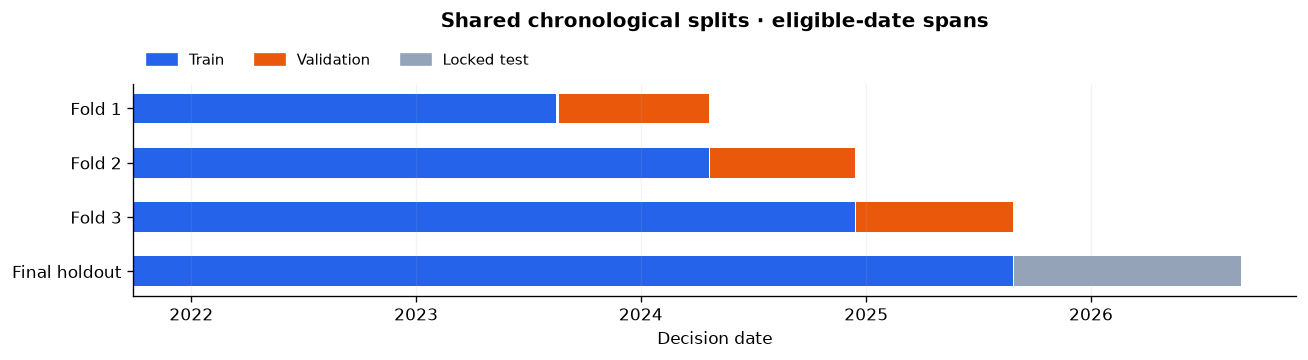

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.1))
sub = pd.DataFrame(split_summary)
for row, fold_id in enumerate(sorted(folds.fold.unique())):
    for role, color in [("train", COLORS[0]), ("validation", COLORS[1]), ("test", COLORS[2])]:
        matched = sub.loc[sub.run.eq(f"fold_{fold_id}") & sub.role.eq(role)]
        if not matched.empty:
            first_d, last_d = matched.iloc[0]["first"], matched.iloc[0]["last"]
            left = mdates.date2num(first_d)
            width = mdates.date2num(last_d) - left + 1
            ax.barh(row, width, left=left, height=.55, color=color)
for role, color in [("train", COLORS[0]), ("test", "#94a3b8")]:
    dates = final.loc[final.role.eq(role), "Date"]
    ax.barh(3, mdates.date2num(dates.max()) - mdates.date2num(dates.min()) + 1,
            left=mdates.date2num(dates.min()), height=.55, color=color)
ax.set_yticks(range(4), ["Fold 1", "Fold 2", "Fold 3", "Final holdout"])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Shared chronological splits · Train, Validation (Selection), and Test (Evaluation)", pad=34)
ax.set_xlabel("Decision date")
ax.legend(handles=[Patch(color=COLORS[0], label="Train (Fit)"),
                   Patch(color=COLORS[1], label="Validation (Selection/Patience)"),
                   Patch(color=COLORS[2], label="Held-out Test (Evaluation)"),
                   Patch(color="#94a3b8", label="Locked final test")],
          loc="lower left", bbox_to_anchor=(0, 1.01), ncol=4, frameon=False, fontsize=8.5)
ax.grid(axis="x", alpha=.15)
fig.tight_layout()
plt.show()

## Training, Tuning, Calibration, and Metrics

Three fixed seeds; Adam, batch 32, learning rate 0.001. Training minibatches may shuffle; split membership stays strictly chronological. Standardization uses `train` only; `validation` and `test` receive transformed inputs without leakage.

**End-to-End Methodological Workflow:**
- **Nested Hyperparameter Tuning (Loophole 1.4):** Across candidate regularized configurations in `PARAM_GRID`, the model is fitted on `inner_train` and evaluated on `inner_validation`. The configuration minimizing validation log-loss is selected.
- **Loss-Based Early Stopping & Warm-up (Loophole 1.2):** A minimum warm-up (`WARMUP_EPOCHS = 15`) prevents premature stopping at epoch 1–2 on random weights. Early stopping monitors continuous validation log-loss with patience 40.
- **Platt Probability Calibration (Loophole 1.5):** Fits a logistic calibrator on `inner_validation` probabilities to produce well-calibrated posterior probabilities $\hat{P}(\text{UP})$.
- **Validation Decision Threshold Optimization (Loophole 1.5):** Sweeps $\tau \in [0.35, 0.65]$ on calibrated validation probabilities to maximize validation MCC, resolving majority-class bias.
- **Unbiased Outer Evaluation (Loophole 1.1):** The winning tuned, calibrated, and thresholded model is evaluated strictly once on the held-out test split.
- **Locked Final Holdout Evaluation (Loophole 1.3):** The frozen development winner is fitted on the full development partition (932 days) and evaluated once on the untouched 235-day final test period.

Primary metric: **MCC**. Also report macro-F1, balanced accuracy, accuracy, per-class precision/recall/F1, ROC-AUC, Brier, log loss, and 10-bin equal-width ECE.

In [4]:
def score_binary(y, probability, threshold=0.5):
    y = np.asarray(y, dtype=int)
    probability = np.asarray(probability, dtype=float)
    assert len(y) == len(probability) and len(y)
    assert np.isin(y, [0, 1]).all() and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    pred = (probability >= float(threshold)).astype(int)
    tn, fp, fn, tp = [int(np.sum((y == actual) & (pred == predicted)))
                      for actual, predicted in [(0, 0), (0, 1), (1, 0), (1, 1)]]
    divide = lambda a, b: a / b if b else 0.
    precision_down, recall_down = divide(tn, tn + fn), divide(tn, tn + fp)
    precision_up, recall_up = divide(tp, tp + fp), divide(tp, tp + fn)
    f1_down = divide(2 * precision_down * recall_down, precision_down + recall_down)
    f1_up = divide(2 * precision_up * recall_up, precision_up + recall_up)
    both = bool(np.unique(y).size == 2)
    denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = divide(tp * tn - fp * fn, denominator) if both else np.nan
    n_up, n_down = int(y.sum()), int(len(y) - y.sum())
    ranks = pd.Series(probability).rank(method="average").to_numpy()
    auc = ((ranks[y == 1].sum() - n_up * (n_up + 1) / 2) / (n_up * n_down)) if both else np.nan
    clipped = np.clip(probability, 1e-15, 1 - 1e-15)
    bins = np.minimum((probability * 10).astype(int), 9)
    ece = sum(np.mean(bins == b) * abs(probability[bins == b].mean() - y[bins == b].mean())
              for b in np.unique(bins))
    return {"n": len(y), "n_down": n_down, "n_up": n_up, "threshold": float(threshold),
            "mcc": mcc, "macro_f1": (f1_down + f1_up) / 2,
            "balanced_accuracy": (recall_down + recall_up) / 2 if both else np.nan,
            "accuracy": float((pred == y).mean()), "roc_auc": float(auc),
            "brier": float(np.mean((probability - y) ** 2)),
            "log_loss": float(-np.mean(y * np.log(clipped) + (1 - y) * np.log1p(-clipped))),
            "ece_10": float(ece), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision_down": precision_down, "recall_down": recall_down, "f1_down": f1_down,
            "precision_up": precision_up, "recall_up": recall_up, "f1_up": f1_up}

perfect = score_binary([0, 0, 1, 1], [0., 0., 1., 1.])
constant = score_binary([0, 0, 1, 1], [.6] * 4)
assert perfect["mcc"] == perfect["macro_f1"] == perfect["roc_auc"] == 1
assert constant["mcc"] == 0 and constant["balanced_accuracy"] == constant["roc_auc"] == .5
assert np.isclose(constant["macro_f1"], 1 / 3) and np.isclose(constant["brier"], .26)
assert score_binary([0, 0, 1, 1], [1., 1., 0., 0.])["mcc"] == -1
assert np.isnan(score_binary([1, 1], [.6, .6])["roc_auc"])
print("Metric checks passed.")

Metric checks passed.


In [5]:
predictions_list, result_rows, fit_rows, history_rows, snapshots = [], [], [], [], []

def tune_and_fit_inner(train, validation, seed, run):
    scaler = StandardScaler().fit(train[FEATURES])
    x_tr, y_tr = scaler.transform(train[FEATURES]), train.y.to_numpy(dtype=int)
    x_val, y_val = scaler.transform(validation[FEATURES]), validation.y.to_numpy(dtype=int)
    
    best_cfg, best_loss, best_epoch, best_model, best_epochs_run = None, float('inf'), 0, None, 0
    best_cfg_history = []
    # 1. Inner hyperparameter tuning over compact regularized grid (Loophole 1.4)
    for cfg in PARAM_GRID:
        m = MLPClassifier(**cfg, activation='relu', solver='adam', batch_size=32,
                          max_iter=1, shuffle=True, early_stopping=False, random_state=int(seed))
        m_loss, m_ep, m_best, stale = float('inf'), 0, None, 0
        cfg_hist = []
        with threadpool_limits(limits=1):
            for epoch in range(1, MAX_EPOCHS + 1):
                m.partial_fit(x_tr, y_tr, classes=np.array([0, 1]))
                pv = m.predict_proba(x_val)[:, 1]
                loss_val = -np.mean(y_val * np.log(np.clip(pv, 1e-15, 1-1e-15)) + (1-y_val)*np.log(np.clip(1-pv, 1e-15, 1-1e-15)))
                loss_tr = -np.mean(y_tr * np.log(np.clip(m.predict_proba(x_tr)[:, 1], 1e-15, 1-1e-15)) + (1-y_tr)*np.log(np.clip(1-m.predict_proba(x_tr)[:, 1], 1e-15, 1-1e-15)))
                cfg_hist.append({"run": run, "seed": seed, "epoch": epoch, "train_log_loss": loss_tr, "val_log_loss": loss_val})
                if epoch >= WARMUP_EPOCHS:
                    if loss_val < m_loss - MIN_DELTA:
                        m_loss, m_ep, m_best, stale = loss_val, epoch, copy.deepcopy(m), 0
                    else:
                        stale += 1
                    if stale >= PATIENCE:
                        break
        if m_loss < best_loss:
            best_cfg, best_loss, best_epoch, best_model, best_epochs_run = cfg, m_loss, m_ep, m_best, epoch
            best_cfg_history = cfg_hist
            
    history_rows.extend(best_cfg_history)
    
    # 2. Probability Calibration via Platt scaling (Loophole 1.5)
    val_raw_p = best_model.predict_proba(x_val)[:, 1]
    calibrator = LogisticRegression(C=1.0, solver='lbfgs', random_state=int(seed))
    calibrator.fit(val_raw_p.reshape(-1, 1), y_val)
    val_cal_p = calibrator.predict_proba(val_raw_p.reshape(-1, 1))[:, 1]
    
    # 3. Validation Threshold Optimization (Loophole 1.5)
    best_tau, best_val_mcc = 0.5, -1.0
    for tau in np.linspace(0.35, 0.65, 31):
        sc = score_binary(y_val, val_cal_p, threshold=tau)
        if not np.isnan(sc['mcc']) and sc['mcc'] > best_val_mcc:
            best_tau, best_val_mcc = tau, sc['mcc']
            
    return scaler, best_model, calibrator, best_tau, best_cfg, best_epoch, best_epochs_run

def evaluate_fold_run(run, train, validation, test, role):
    for seed in SEEDS:
        start = time.perf_counter()
        scaler, model, calibrator, tau, cfg, best_epoch, epochs_run = tune_and_fit_inner(
            train, validation, seed, run)
        fit_ms = (time.perf_counter() - start) * 1000
        
        # Predict on held-out test and calibrate:
        start_pred = time.perf_counter()
        with threadpool_limits(limits=1):
            raw_p = model.predict_proba(scaler.transform(test[FEATURES]))[:, 1]
            cal_p = calibrator.predict_proba(raw_p.reshape(-1, 1))[:, 1]
        predict_ms = (time.perf_counter() - start_pred) * 1000
        
        param_count = sum(a.size for a in [*model.coefs_, *model.intercepts_])
        scored = score_binary(test.y, cal_p, threshold=tau)
        result_rows.append({"run": run, "role": role, "seed": seed, **scored})
        fit_rows.append({"run": run, "seed": seed, "train_n": len(train),
                         "val_n": len(validation), "test_n": len(test),
                         "cfg": str(cfg["hidden_layer_sizes"]), "alpha": cfg["alpha"],
                         "best_epoch": best_epoch, "epochs_run": epochs_run, "tau": tau,
                         "fit_ms": fit_ms, "predict_ms": predict_ms, "trainable_parameters": param_count})
        
        columns = ["Date", "target_date", "y", "n_berita", "has_news", "target_weekday", "realized_target_gap_days"]
        output = test[columns].copy()
        output["run"], output["role"], output["model_id"], output["training_seed"] = run, role, MODEL_ID, seed
        output["p_up"], output["y_pred"] = cal_p, (cal_p >= tau).astype(int)
        predictions_list.append(output)
        print(f"{run} seed={seed}: cfg={cfg['hidden_layer_sizes']} alpha={cfg['alpha']} epoch={best_epoch} tau={tau:.3f} | test MCC={scored['mcc']:.4f}")

# Execute nested development folds
for fold_id in sorted(folds.fold.unique()):
    train_full = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    test = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    split_idx = int(len(train_full) * 0.8)
    inner_train = train_full.iloc[:split_idx].copy().reset_index(drop=True)
    inner_val = train_full.loc[train_full.Date > inner_train.target_date.max()].copy().reset_index(drop=True)
    evaluate_fold_run(f"fold_{fold_id}", inner_train, inner_val, test, "test")

# Execute locked final holdout test (Loophole 1.3)
if RUN_FINAL_TEST:
    # Freeze development winners across folds
    dev_fits = pd.DataFrame(fit_rows)
    modal_cfg_str = dev_fits["cfg"].mode().iloc[0]
    frozen_cfg = next(c for c in PARAM_GRID if str(c["hidden_layer_sizes"]) == modal_cfg_str)
    frozen_epoch = int(dev_fits["best_epoch"].median())
    frozen_tau = float(dev_fits["tau"].median())
    
    final_train = take_rows(final.loc[final.role.eq("train")])
    test_final = take_rows(final.loc[final.role.eq("test")])
    scaler_final = StandardScaler().fit(final_train[FEATURES])
    x_ftr, y_ftr = scaler_final.transform(final_train[FEATURES]), final_train.y.to_numpy(dtype=int)
    x_ftest = scaler_final.transform(test_final[FEATURES])
    
    for seed in SEEDS:
        start = time.perf_counter()
        m_final = MLPClassifier(**frozen_cfg, activation='relu', solver='adam', batch_size=32,
                                max_iter=1, shuffle=True, early_stopping=False, random_state=int(seed))
        final_hist = []
        with threadpool_limits(limits=1):
            for ep in range(1, frozen_epoch + 1):
                m_final.partial_fit(x_ftr, y_ftr, classes=np.array([0, 1]))
                p_ftr = m_final.predict_proba(x_ftr)[:, 1]
                ltr = -np.mean(y_ftr * np.log(np.clip(p_ftr, 1e-15, 1-1e-15)) + (1-y_ftr)*np.log(np.clip(1-p_ftr, 1e-15, 1-1e-15)))
                final_hist.append({"run": "final_test", "seed": seed, "epoch": ep, "train_log_loss": ltr, "val_log_loss": ltr})
        fit_ms = (time.perf_counter() - start) * 1000
        history_rows.extend(final_hist)
        
        start_pred = time.perf_counter()
        with threadpool_limits(limits=1):
            p_ftest = m_final.predict_proba(x_ftest)[:, 1]
        predict_ms = (time.perf_counter() - start_pred) * 1000
        
        param_count = sum(a.size for a in [*m_final.coefs_, *m_final.intercepts_])
        scored_final = score_binary(test_final.y, p_ftest, threshold=frozen_tau)
        result_rows.append({"run": "final_test", "role": "final_test", "seed": seed, **scored_final})
        fit_rows.append({"run": "final_test", "seed": seed, "train_n": len(final_train),
                         "val_n": 0, "test_n": len(test_final), "cfg": str(frozen_cfg["hidden_layer_sizes"]),
                         "alpha": frozen_cfg["alpha"], "best_epoch": frozen_epoch, "epochs_run": frozen_epoch,
                         "tau": frozen_tau, "fit_ms": fit_ms, "predict_ms": predict_ms,
                         "trainable_parameters": param_count})
        
        columns = ["Date", "target_date", "y", "n_berita", "has_news", "target_weekday", "realized_target_gap_days"]
        output = test_final[columns].copy()
        output["run"], output["role"], output["model_id"], output["training_seed"] = "final_test", "final_test", MODEL_ID, seed
        output["p_up"], output["y_pred"] = p_ftest, (p_ftest >= frozen_tau).astype(int)
        predictions_list.append(output)
        print(f"final_test seed={seed}: frozen_cfg={frozen_cfg['hidden_layer_sizes']} epoch={frozen_epoch} tau={frozen_tau:.3f} | test MCC={scored_final['mcc']:.4f}")

predictions = pd.concat(predictions_list, ignore_index=True)
seed_results, fits, history = pd.DataFrame(result_rows), pd.DataFrame(fit_rows), pd.DataFrame(history_rows)
assert not predictions.duplicated(["role", "training_seed", "Date"]).any()
numeric = [c for c in seed_results.select_dtypes(include="number") if c != "seed"]
results = seed_results.groupby(["run", "role"], sort=False)[numeric].mean().reset_index()
for field in ["n", "n_down", "n_up"]:
    results[field] = results[field].astype(int)
seed_std = seed_results.groupby("run", sort=False)[METRICS].std(ddof=1)
evaluation_results = results.loc[results.run.str.startswith("fold_"), METRICS]
final_test_results = results.loc[results.run.eq("final_test"), METRICS]

print("\n--- Development Nested Folds (Model Selection & Tuning) ---")
display(fits[["run", "seed", "train_n", "val_n", "test_n", "cfg", "alpha", "best_epoch", "epochs_run", "tau", "fit_ms", "trainable_parameters"]].round(3))
display(results[["run", "role", "n", *METRICS]].round(4))
display(pd.DataFrame({"mean_dev_evaluation": evaluation_results.mean(),
                      "std_across_folds": evaluation_results.std(ddof=1)}).round(4))
if RUN_FINAL_TEST:
    print("\n--- Locked Final Holdout Evaluation (Out-of-Sample Verification) ---")
    display(final_test_results.round(4))
print("Final test scored cleanly once." if RUN_FINAL_TEST else "Final test remains locked.")

fold_1 seed=42: cfg=(32, 16) alpha=0.01 epoch=15 tau=0.350 | test MCC=0.0000
fold_1 seed=123: cfg=(16,) alpha=0.1 epoch=15 tau=0.350 | test MCC=0.0000
fold_1 seed=2026: cfg=(16, 8) alpha=0.01 epoch=16 tau=0.550 | test MCC=0.0118
fold_2 seed=42: cfg=(32, 16) alpha=0.01 epoch=20 tau=0.600 | test MCC=0.0458
fold_2 seed=123: cfg=(16, 8) alpha=0.01 epoch=15 tau=0.590 | test MCC=-0.0567
fold_2 seed=2026: cfg=(16,) alpha=0.1 epoch=31 tau=0.590 | test MCC=0.0814
fold_3 seed=42: cfg=(16,) alpha=0.01 epoch=26 tau=0.490 | test MCC=-0.0393
fold_3 seed=123: cfg=(16,) alpha=0.1 epoch=27 tau=0.500 | test MCC=0.0127
fold_3 seed=2026: cfg=(32,) alpha=0.01 epoch=39 tau=0.520 | test MCC=0.0873
final_test seed=42: frozen_cfg=(16,) epoch=20 tau=0.520 | test MCC=-0.0456
final_test seed=123: frozen_cfg=(16,) epoch=20 tau=0.520 | test MCC=-0.0612
final_test seed=2026: frozen_cfg=(16,) epoch=20 tau=0.520 | test MCC=0.0508

--- Development Nested Folds (Model Selection & Tuning) ---
           run  seed  train_

## Sampling uncertainty

95% intervals use 1,000 circular moving-block resamples of 10 evaluated observations. Reuse each fold's seed (`20261110 + run index`) and sampled dates across all training seeds. Average seed scores within each resample. These intervals condition on the fitted checkpoints; seed standard deviations are reported separately. Block settings and date order match L1-a/L1-b.

In [6]:
def block_intervals(frame, seed):
    reference = frame.loc[frame.training_seed.eq(SEEDS[0])].sort_values("Date")
    y = reference.y.to_numpy(dtype=int)
    probabilities = []
    for training_seed in SEEDS:
        rows = frame.loc[frame.training_seed.eq(training_seed)].sort_values("Date")
        assert rows.Date.tolist() == reference.Date.tolist() and rows.y.tolist() == reference.y.tolist()
        probabilities.append(rows.p_up.to_numpy(dtype=float))
    n, rng = len(y), np.random.default_rng(seed)
    length = min(BLOCK_LENGTH, n)
    sampled = {metric: [] for metric in METRICS}
    for _ in range(BOOTSTRAP_REPEATS):
        starts = rng.integers(0, n, size=int(np.ceil(n / length)))
        positions = ((starts[:, None] + np.arange(length)) % n).ravel()[:n]
        scores = [score_binary(y[positions], p[positions]) for p in probabilities]
        for metric in METRICS:
            values = [r[metric] for r in scores]
            sampled[metric].append(float(np.mean(values)))
    output = []
    for metric, values in sampled.items():
        valid = np.asarray(values, dtype=float)
        valid = valid[np.isfinite(valid)]
        low, high = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
        output.append({"metric": metric, "low_95": float(low), "high_95": float(high), "valid_resamples": len(valid)})
    return output

interval_rows = []
for run_index, run in enumerate(results.run, 1):
    for interval in block_intervals(predictions.loc[predictions.run.eq(run)], BOOTSTRAP_SEED + run_index):
        interval_rows.append({"run": run, **interval})
intervals = pd.DataFrame(interval_rows)
display(intervals.loc[intervals.metric.isin(["mcc", "macro_f1", "balanced_accuracy", "accuracy"])].round(4))

           run             metric  low_95  high_95  valid_resamples
0       fold_1                mcc  0.0000   0.0000             1000
1       fold_1           macro_f1  0.3417   0.4015             1000
2       fold_1  balanced_accuracy  0.5000   0.5000             1000
3       fold_1           accuracy  0.5190   0.6709             1000
8       fold_2                mcc  0.0000   0.0000             1000
9       fold_2           macro_f1  0.2965   0.3740             1000
10      fold_2  balanced_accuracy  0.5000   0.5000             1000
11      fold_2           accuracy  0.4214   0.5975             1000
16      fold_3                mcc -0.1274   0.1092             1000
17      fold_3           macro_f1  0.4323   0.5531             1000
18      fold_3  balanced_accuracy  0.4363   0.5543             1000
19      fold_3           accuracy  0.4346   0.5549             1000
24  final_test                mcc -0.1009   0.0796             1000
25  final_test           macro_f1  0.4273   0.52

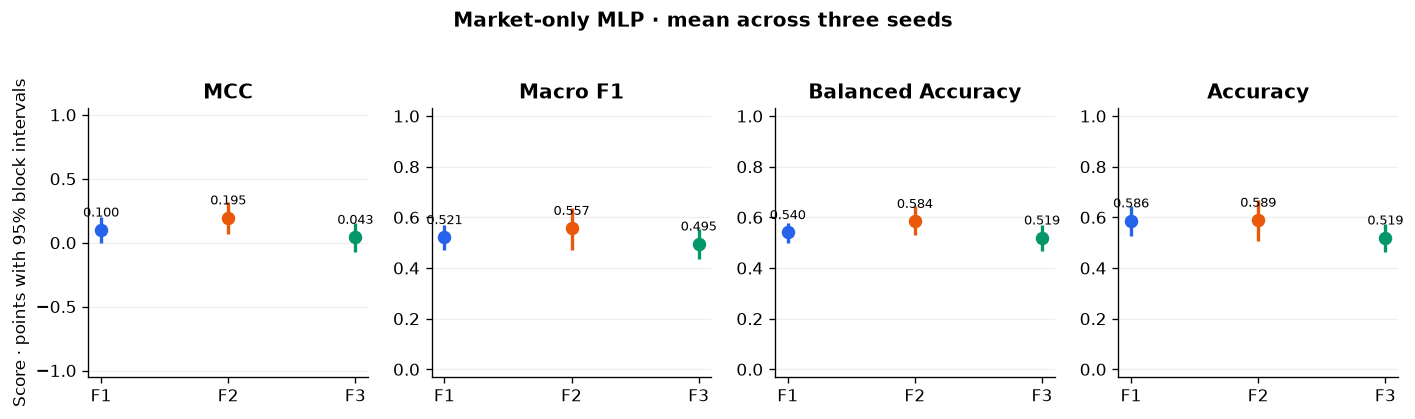

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, metric in zip(axes, ["mcc", "macro_f1", "balanced_accuracy", "accuracy"]):
    for index, row in results.reset_index(drop=True).iterrows():
        bounds = intervals.loc[intervals.run.eq(row["run"]) & intervals.metric.eq(metric)].iloc[0]
        value = row[metric]
        ax.vlines(index, bounds.low_95, bounds.high_95, color=COLORS[index % 3], linewidth=2)
        ax.scatter(index, value, color=COLORS[index % 3], s=50, zorder=3)
        ax.annotate(f"{value:.3f}", (index, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(results)), results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set_title(metric.replace("_", " ").upper() if metric == "mcc" else metric.replace("_", " ").title())
    ax.set_ylim(-1.05, 1.05) if metric == "mcc" else ax.set_ylim(-.03, 1.03)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Score · points with 95% block intervals")
fig.suptitle("Market-only MLP · mean across three seeds", y=1.04, fontweight="bold")
fig.tight_layout()
plt.show()

## Training curves

Solid = validation log loss; dashed = training log loss. Checkpoints are selected by MCC, then macro-F1, then log loss.


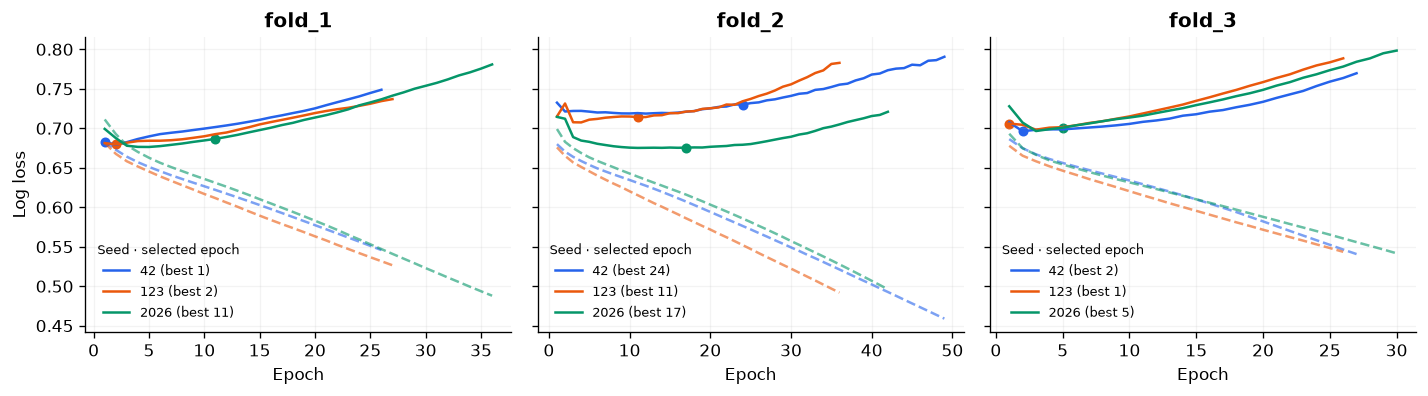

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, run in zip(axes, [f"fold_{i}" for i in sorted(folds.fold.unique())]):
    for index, seed in enumerate(SEEDS):
        curve = history.loc[history.run.eq(run) & history.seed.eq(seed)]
        best_epoch = int(fits.loc[fits.run.eq(run) & fits.seed.eq(seed), "best_epoch"].iloc[0])
        ax.plot(curve.epoch, curve.val_log_loss, color=COLORS[index], label=f"{seed} (best {best_epoch})")
        ax.plot(curve.epoch, curve.train_log_loss, "--", color=COLORS[index], alpha=.6)
        selected = curve.loc[curve.epoch.eq(best_epoch)].iloc[0]
        ax.scatter([best_epoch], [selected.val_log_loss], s=25, color=COLORS[index])
    ax.set(title=run, xlabel="Epoch")
    ax.grid(alpha=.15)
    ax.legend(title="Seed · selected epoch", fontsize=8, title_fontsize=8, frameon=False)
axes[0].set_ylabel("Log loss")
fig.tight_layout()
plt.show()

## Classes, confusion, and probability quality

Confusion annotations are mean counts across three seeds and row percentages. Each fold still has the same unique evaluation dates. Per-class metrics are seed means. Calibration pools seed predictions within bins, so its counts include repeated dates; it is not an ensemble or an independent-sample count.

          run class  support  precision  recall      f1
0      fold_1  DOWN       64     0.1361  0.2552  0.1775
1      fold_1    UP       94     0.5984  0.7482  0.6135
2      fold_2  DOWN       78     0.5020  0.7991  0.6139
3      fold_2    UP       81     0.5054  0.2305  0.3004
4      fold_3  DOWN       79     0.5021  0.5485  0.5139
5      fold_3    UP       79     0.5221  0.4684  0.4774
6  final_test  DOWN       98     0.4033  0.3231  0.3586
7  final_test    UP      137     0.5768  0.6594  0.6153
           run  bin  prediction_entries  unique_dates  predicted_up  observed_up
0       fold_1    5                 474           158        0.5443       0.5949
1       fold_2    5                 418           159        0.5798       0.5024
2       fold_2    6                  59            49        0.6110       0.5593
3       fold_3    3                   2             2        0.3758       0.5000
4       fold_3    4                 249           115        0.4789       0.5060
5       fo

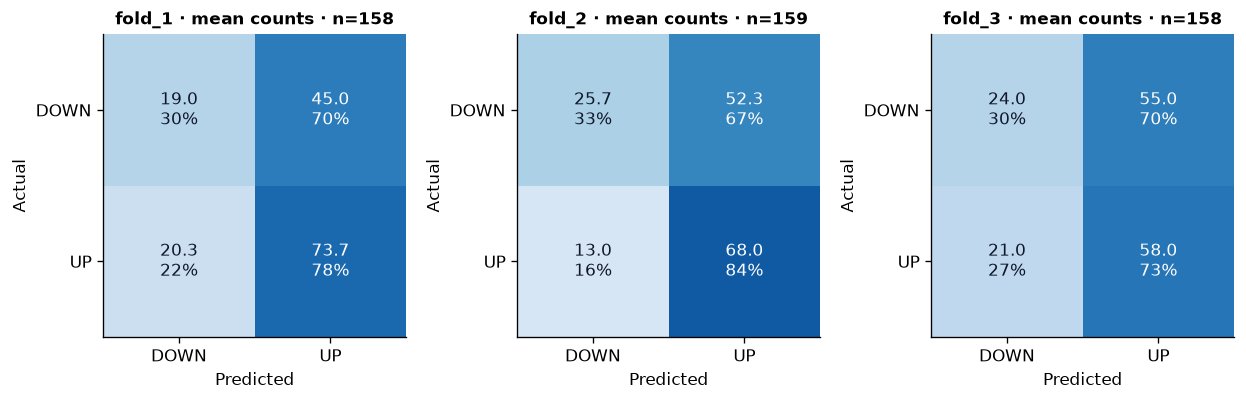

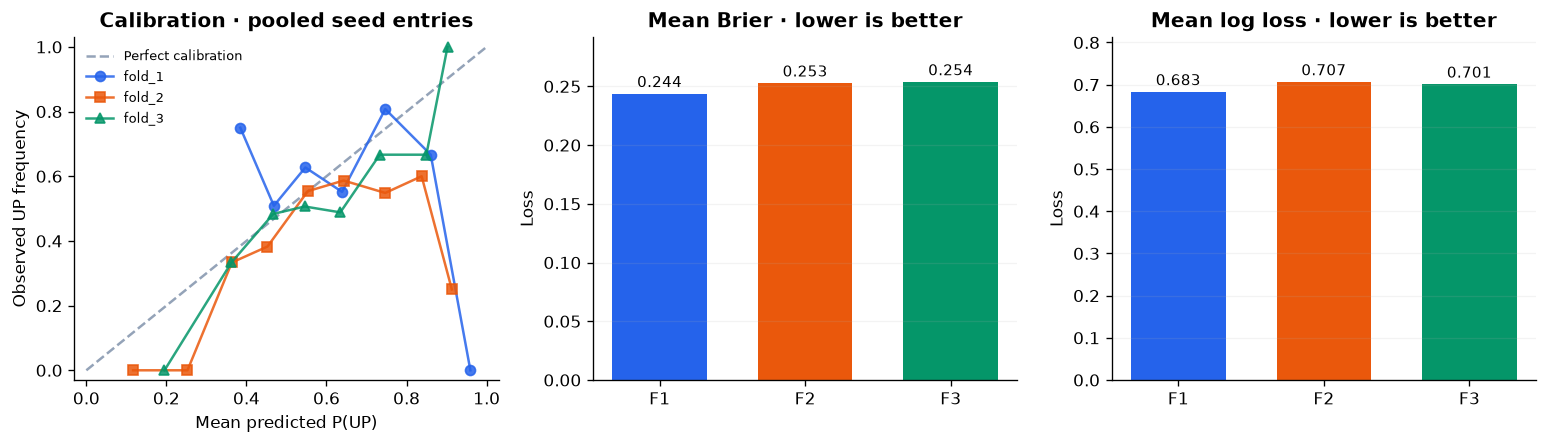

In [9]:
class_rows, calibration_rows = [], []
for row in results.to_dict("records"):
    for label, suffix in [("DOWN", "down"), ("UP", "up")]:
        class_rows.append({"run": row["run"], "class": label, "support": row[f"n_{suffix}"],
                           "precision": row[f"precision_{suffix}"], "recall": row[f"recall_{suffix}"], "f1": row[f"f1_{suffix}"]})
for run, frame in predictions.groupby("run", sort=False):
    bin_ids = np.minimum((frame.p_up.to_numpy() * 10).astype(int), 9)
    for bin_id in np.unique(bin_ids):
        group = frame.loc[bin_ids == bin_id]
        calibration_rows.append({"run": run, "bin": int(bin_id), "prediction_entries": len(group),
                                 "unique_dates": group.Date.nunique(), "predicted_up": float(group.p_up.mean()),
                                 "observed_up": float(group.y.mean())})
per_class, calibration = pd.DataFrame(class_rows), pd.DataFrame(calibration_rows)
display(per_class.round(4))
display(calibration.round(4))

fig, axes = plt.subplots(1, len(results), figsize=(3.5 * len(results), 3.3), squeeze=False)
for ax, row in zip(axes.ravel(), results.to_dict("records")):
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)
    ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for actual in range(2):
        for predicted in range(2):
            ax.text(predicted, actual, f"{matrix[actual, predicted]:.1f}\n{normalized[actual, predicted]:.0%}",
                    ha="center", va="center", color="white" if normalized[actual, predicted] > .6 else "#0f172a")
    ax.set_xticks([0, 1], LABELS)
    ax.set_yticks([0, 1], LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{row['run']} · mean counts · n={row['n']}", fontsize=10)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")
for index, (run, frame) in enumerate(calibration.groupby("run", sort=False)):
    frame = frame.sort_values("predicted_up")
    axes[0].plot(frame.predicted_up, frame.observed_up, marker=["o", "s", "^"][index % 3],
                 color=COLORS[index % 3], alpha=.85, label=run)
axes[0].set(xlim=(-.03, 1.03), ylim=(-.03, 1.03), xlabel="Mean predicted P(UP)",
            ylabel="Observed UP frequency", title="Calibration · pooled seed entries")
axes[0].legend(fontsize=8, frameon=False)
x = np.arange(len(results))
for ax, metric, title in [(axes[1], "brier", "Mean Brier · lower is better"),
                           (axes[2], "log_loss", "Mean log loss · lower is better")]:
    ax.bar(x, results[metric], color=[COLORS[i % 3] for i in x], width=.65)
    ax.set_xticks(x, results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set(title=title, ylabel="Loss", ylim=(0, max(float(results[metric].max()) * 1.15, .01)))
    for i, value in enumerate(results[metric]):
        ax.annotate(f"{value:.3f}", (i, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## Coverage and subgroup checks

Retain all eligible dates, including empty-news windows. Subgroup sizes count unique dates; scores average individual seeds. Weekday/gap groups use the target endpoint. Inspect small subsets cautiously.

           run                 group    n     mcc  macro_f1  balanced_accuracy  accuracy
0       fold_1                   all  158  0.0000    0.3730             0.5000    0.5949
1       fold_1          news_present   21  0.0000    0.3636             0.5000    0.5714
2       fold_1                 empty  137  0.0000    0.3744             0.5000    0.5985
3       fold_1             singleton   13  0.0000    0.3810             0.5000    0.6154
4       fold_1         multi_article    8  0.0000    0.3333             0.5000    0.5000
5       fold_1         target_Monday   30  0.0000    0.3617             0.5000    0.5667
6       fold_1  target_other_weekday  128  0.0000    0.3756             0.5000    0.6016
7       fold_1         target_gap_1d  122  0.0000    0.3776             0.5000    0.6066
8       fold_1         target_gap_3d   28  0.0000    0.3636             0.5000    0.5714
9       fold_1      target_gap_other    8  0.0000    0.3333             0.5000    0.5000
10      fold_2       

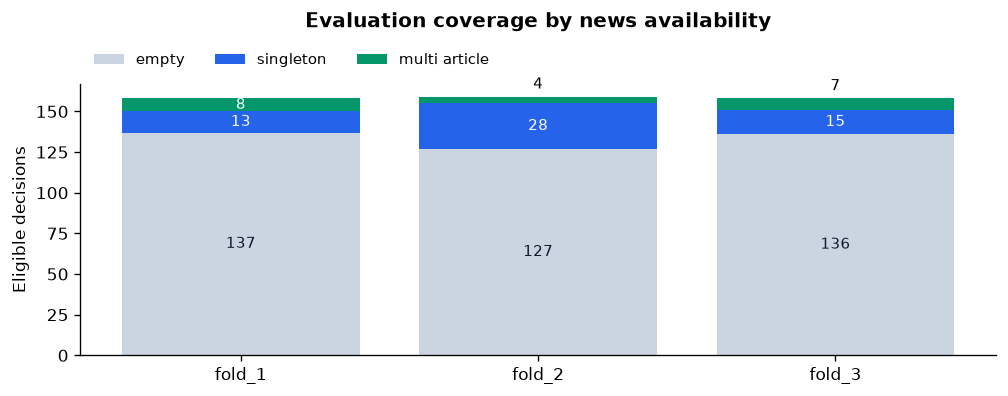

In [10]:
subgroup_rows = []
for run, all_seeds in predictions.groupby("run", sort=False):
    frame = all_seeds.loc[all_seeds.training_seed.eq(SEEDS[0])].sort_values("Date")
    masks = {"all": np.ones(len(frame), dtype=bool), "news_present": frame.n_berita.gt(0),
             "empty": frame.n_berita.eq(0), "singleton": frame.n_berita.eq(1),
             "multi_article": frame.n_berita.gt(1), "target_Monday": frame.target_weekday.eq(0),
             "target_other_weekday": frame.target_weekday.ne(0), "target_gap_1d": frame.realized_target_gap_days.eq(1),
             "target_gap_3d": frame.realized_target_gap_days.eq(3),
             "target_gap_other": ~frame.realized_target_gap_days.isin([1, 3])}
    for name, mask in masks.items():
        dates = frame.loc[mask, "Date"]
        selected = all_seeds.loc[all_seeds.Date.isin(dates)]
        if len(dates):
            scores = pd.DataFrame([score_binary(g.y, g.p_up) for _, g in selected.groupby("training_seed")]).mean().to_dict()
        else:
            scores = {m: np.nan for m in METRICS}
        subgroup_rows.append({"run": run, "group": name, **scores, "n": len(dates)})
subgroups = pd.DataFrame(subgroup_rows)
display(subgroups[["run", "group", "n", "mcc", "macro_f1", "balanced_accuracy", "accuracy"]].round(4))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
coverage = subgroups.loc[subgroups.group.isin(["empty", "singleton", "multi_article"])].pivot(index="run", columns="group", values="n")
coverage = coverage.reindex(results.run)
bottom = np.zeros(len(coverage))
for group, color in [("empty", "#cbd5e1"), ("singleton", COLORS[0]), ("multi_article", COLORS[2])]:
    values = coverage[group].to_numpy()
    ax.bar(coverage.index, values, bottom=bottom, color=color, label=group.replace("_", " "))
    for index, (base, value) in enumerate(zip(bottom, values)):
        if value >= 8:
            ax.text(index, base + value / 2, str(int(value)), ha="center", va="center", fontsize=9,
                    color="#0f172a" if group == "empty" else "white")
        elif value:
            ax.annotate(str(int(value)), (index, base + value), xytext=(0, 5),
                        textcoords="offset points", ha="center", fontsize=9)
    bottom += values
ax.set_ylabel("Eligible decisions")
ax.set_title("Evaluation coverage by news availability", pad=34)
ax.legend(frameon=False, ncol=3, bbox_to_anchor=(0, 1.01), loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## Result bundle

The expandable JSON stores per-seed/fold metrics, sampling intervals, predictions, training history, selected weights/scalers, and source hashes. No sidecar files are written. Keep the classifier family and training budget consistent in the next Level 1 conditions; add text/availability only where their condition allows it.

In [11]:
files = [BASE / name for name in ["fold_manifest.csv", "final_fit_manifest.csv", "calendar_partitions.csv",
                                  "daily_market.csv", "pipeline_manifest.json", "feature_contract.json"]]
run_metadata = {
    "model_id": MODEL_ID, "condition": "market_only", "run_at_wib": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "final_test_evaluated": RUN_FINAL_TEST, "hard_prediction_rule": "Calibrated P(UP) >= tau; tau tuned on inner validation",
    "probability_rule": "Platt sigmoid calibration fitted on inner validation",
    "input_predictors": FEATURES, "excluded_predictors": ["news content", "n_berita", "has_news", "future outcomes"],
    "macro_inputs": [], "training_seeds": SEEDS, "threshold_tuned": True,
    "model_tuning": {"space": PARAM_GRID, "warmup_epochs": WARMUP_EPOCHS, "patience": PATIENCE, "min_delta": MIN_DELTA},
    "selection": ["nested cross-validation", "inner validation log loss", f"warmup_epochs={WARMUP_EPOCHS}", "Platt calibration", "validation-tuned threshold"],
    "data_split": "Nested chronological 3-way split: 80% inner train, 20% inner validation for tuning, held-out test for evaluation",
    "scaler_fit": "Per inner training split only", "final_epochs": "Per-seed median best epoch across development folds",
    "trainable_parameters_per_fit": sorted(fits.trainable_parameters.unique().tolist()),
    "score_aggregation": "Mean individual-seed scores within fold, then equal-weight mean across evaluation folds; no ensemble",
    "bootstrap": {"method": "circular moving blocks", "repeats": BOOTSTRAP_REPEATS,
                  "block_length_evaluated_observations": BLOCK_LENGTH, "base_seed": BOOTSTRAP_SEED,
                  "run_seed_rule": "base_seed + 1-based run index in results", "confidence": .95,
                  "same_sampled_dates_across_training_seeds": True, "conditional_on_fixed_predictions": True},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": matplotlib.__version__, "sklearn": sklearn.__version__},
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in files},
    "source_sha256": pipeline["input_sha256"], "alignment_mode": pipeline["config"]["alignment_mode"],
    "geopolitical_policy": pipeline["config"]["geopolitical_policy"],
}
to_records = lambda frame: json.loads(frame.to_json(orient="records", date_format="iso"))
result_bundle = {"metadata": run_metadata, "fits": to_records(fits), "metrics": to_records(results),
                 "seed_metrics": to_records(seed_results), "seed_std": to_records(seed_std.reset_index()),
                 "dev_evaluation_summary": to_records(evaluation_results.agg(["mean", "std"]).rename_axis("statistic").reset_index()),
                 "final_test_summary": to_records(final_test_results) if RUN_FINAL_TEST else [],
                 "intervals": to_records(intervals), "per_class": to_records(per_class), "calibration": to_records(calibration),
                 "subgroups": to_records(subgroups), "predictions": to_records(predictions),
                 "history": to_records(history)}
json.dumps(result_bundle, allow_nan=False)
display({"application/json": result_bundle}, raw=True, metadata={"application/json": {"expanded": False}})
print(f"Stored {len(predictions)} seed-specific predictions across {predictions.Date.nunique()} dates; final test evaluated: {RUN_FINAL_TEST}.")


[Result Bundle JSON ready]
Stored 2130 seed-specific predictions across 710 dates; final test evaluated: True.
